In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
from modules.utils import *

import gurobipy as gp
from gurobipy import GRB
from itertools import combinations

import matplotlib.pyplot as plt

In [2]:
df_a1 = pd.read_csv("data/Area_1.txt", sep="\t")
df_a2 = pd.read_csv("data/Area_2.txt", sep="\t")
df_a3 = pd.read_csv("data/Area_3.txt", sep="\t")

df_a1.head()


distance_matrix_area1 = create_distance_matrix(df_a1)
distance_matrix_area2 = create_distance_matrix(df_a2)
distance_matrix_area3 = create_distance_matrix(df_a3)

check_symmetric_matrix(distance_matrix_area1)
print(distance_matrix_area1)

               Warszawa  Skierniewice       Łódź      Konin    Sieradz  \
Warszawa       0.000000      8.544004  16.552945  32.015621  29.732137   
Skierniewice   8.544004      0.000000   8.062258  24.083189  21.189620   
Łódź          16.552945      8.062258   0.000000  18.027756  13.341664   
Konin         32.015621     24.083189  18.027756   0.000000   9.848858   
Sieradz       29.732137     21.189620  13.341664   9.848858   0.000000   
Piotrków      17.804494     11.401754   8.062258  24.698178  17.464249   
Radom         15.132746     15.620499  18.788294  36.769553  30.413813   

               Piotrków      Radom  
Warszawa      17.804494  15.132746  
Skierniewice  11.401754  15.620499  
Łódź           8.062258  18.788294  
Konin         24.698178  36.769553  
Sieradz       17.464249  30.413813  
Piotrków       0.000000  13.038405  
Radom         13.038405   0.000000  


In [3]:
# Defining and solving the mathematical model
R = [1, 2, 3]

D = {
    1: distance_matrix_area1,
    2: distance_matrix_area2,
    3: distance_matrix_area3,
}

V = {r: list(D[r].index) for r in R}
E = {r: list(combinations(V[r], 2)) for r in R}
N = {r: len(V[r]) for r in R}

s = {1: "Warszawa", 2: "Kielce", 3: "Opole"}
e = {1: "Radom", 2: "Gliwice", 3: "Jelenia Góra"}
K = {1: 4, 2: 5, 3: 5}


cities = [i for r in R for i in V[r]]
edges = [(i, j) for r in R for i, j in E[r]]
arcs = [(r, i, j) for r in R for i in V[r] for j in V[r] if i != j]

model = gp.Model("Problem_1")

delta = model.addVars(cities, vtype=GRB.BINARY, name="delta")
Phi = model.addVars(edges, vtype=GRB.BINARY, name="Phi")
f = model.addVars(arcs, vtype=GRB.CONTINUOUS, lb=0, name="f")

# Both directions refer to the same undirected edge variable.
for r in R:
    for i, j in E[r]:
        Phi[j, i] = Phi[i, j]

model.setObjective(
    gp.quicksum(Phi[i, j] * D[r].loc[i, j] for r in R for i, j in E[r]),
    GRB.MINIMIZE,
)

for r in R:
    model.addConstr(delta[s[r]] == 1)
    model.addConstr(delta[e[r]] == 1)

    model.addConstr(gp.quicksum(delta[i] for i in V[r]) >= K[r])

    for i in [s[r], e[r]]:
        model.addConstr(
            gp.quicksum(Phi[i, j] for j in V[r] if j != i) == delta[i]
        )

    for i in V[r]:
        if i not in [s[r], e[r]]:
            model.addConstr(
                gp.quicksum(Phi[i, j] for j in V[r] if j != i) == 2 * delta[i]
            )

    for i in V[r]:
        if i != s[r]:
            model.addConstr(
                gp.quicksum(f[r, j, i] for j in V[r] if j != i)
                - gp.quicksum(f[r, i, j] for j in V[r] if j != i)
                == delta[i]
            )

    model.addConstr(
        gp.quicksum(f[r, s[r], j] for j in V[r] if j != s[r])
        - gp.quicksum(f[r, j, s[r]] for j in V[r] if j != s[r])
        == gp.quicksum(delta[i] for i in V[r] if i != s[r])
    )

    for i in V[r]:
        for j in V[r]:
            if i != j:
                model.addConstr(f[r, i, j] <= (N[r] - 1) * Phi[i, j])

model.addConstr(delta["Konin"] + delta["Kalisz"] >= 1)

model.addConstr(
    delta["Bytom"] + delta["Sosnowiec"] + delta["Katowice"] <= 1
)

model.addConstr(
    delta["Wodzisław Śląski"] + delta["Jastrzębie-Zdrój"] <= 1
)

model.addConstr(
    delta["Poznań"] + delta["Zielona Góra"] + delta["Leszno"] >= 1
)

model.optimize()

if model.Status == GRB.OPTIMAL:
    print(f"Minimum cable length within the areas: {model.ObjVal:.2f}")

    coordinates = pd.concat([df_a1, df_a2, df_a3]).set_index("City")[["x", "y"]]
    fixed_connections = sum(
        np.linalg.norm(coordinates.loc[e[r]].to_numpy() - coordinates.loc[s[r + 1]].to_numpy())
        for r in R[:-1]
    )
    print(f"Minimum cable length including fixed connections: {model.ObjVal + fixed_connections:.2f}")

    full_route = []

    for r in R:
        route = [s[r]]
        previous = None
        current = s[r]

        while current != e[r]:
            next_city = next(
                j for j in V[r]
                if j != current and j != previous and Phi[current, j].X > 0.5
            )

            route.append(next_city)
            previous, current = current, next_city

        full_route.extend(route)

    print("Cities in order:", " -> ".join(full_route))
    write_solution(full_route, model.ObjVal, fixed_connections)
else:
    print(f"No optimal solution found. Gurobi status: {model.Status}")

Set parameter Username


Set parameter LicenseID to value 2874895
Academic license - for non-commercial use only - expires 2027-10-15
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[arm] - Darwin 25.6.0 25G83)

CPU model: Apple M1 Pro
Thread count: 10 physical cores, 10 logical processors, using up to 10 threads

Optimize a model with 269 rows, 332 columns and 1134 nonzeros
Model fingerprint: 0x0997007b
Variable types: 204 continuous, 128 integer (128 binary)
Coefficient statistics:
  Matrix range     [1e+00, 9e+00]
  Objective range  [2e+00, 4e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+00]
Presolve removed 119 rows and 149 columns
Presolve time: 0.01s
Presolved: 150 rows, 183 columns, 624 nonzeros
Variable types: 114 continuous, 69 integer (69 binary)
Found heuristic solution: objective 204.7642203
Found heuristic solution: objective 186.5901346

Root relaxation: objective 1.220205e+02, 100 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Ob

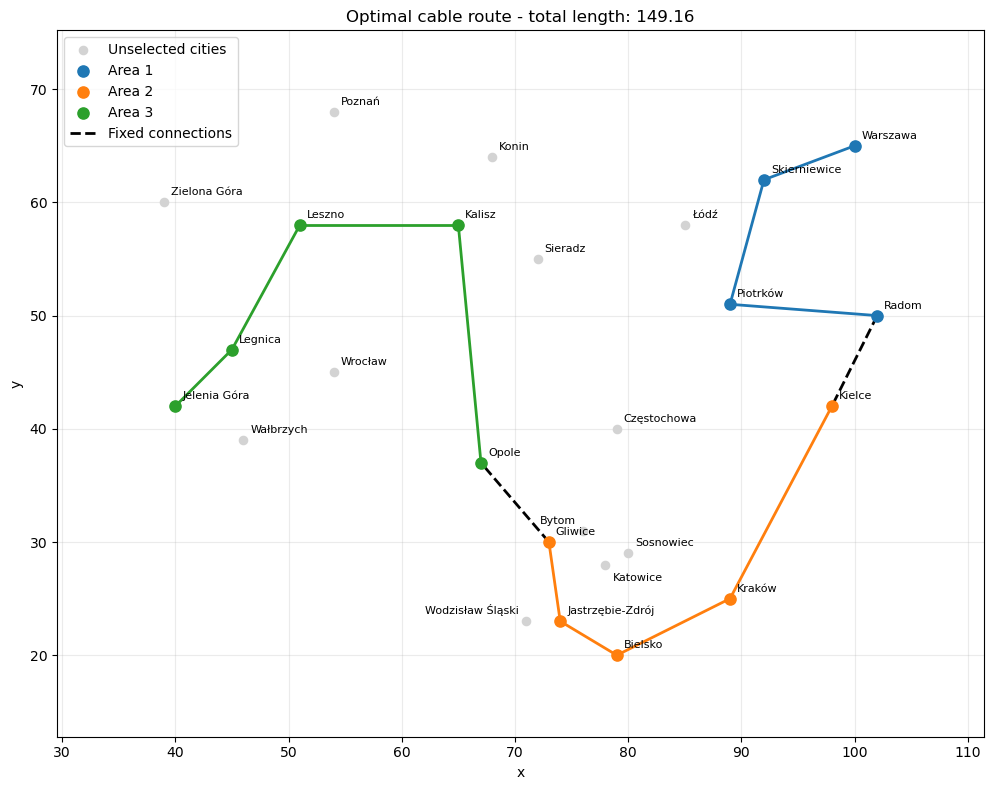

In [4]:
if model.Status == GRB.OPTIMAL:
    fig, ax = plt.subplots(figsize=(12, 8))
    colors = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}

    ax.scatter(coordinates["x"], coordinates["y"], color="lightgray", s=35,
               label="Unselected cities", zorder=3)

    for r in R:
        selected = [i for i in V[r] if delta[i].X > 0.5]
        ax.scatter(coordinates.loc[selected, "x"], coordinates.loc[selected, "y"],
                   color=colors[r], s=65, label=f"Area {r}", zorder=4)

        for i, j in E[r]:
            if Phi[i, j].X > 0.5:
                ax.plot(coordinates.loc[[i, j], "x"], coordinates.loc[[i, j], "y"],
                        color=colors[r], linewidth=2, zorder=2)

    for r in R[:-1]:
        connection = [e[r], s[r + 1]]
        ax.plot(coordinates.loc[connection, "x"], coordinates.loc[connection, "y"],
                color="black", linestyle="--", linewidth=2,
                label="Fixed connections" if r == R[0] else None, zorder=2)

    label_offsets = {
        "Wodzisław Śląski": (-5, 5),
        "Bytom": (-5, 5),
        "Katowice": (5, -12),
    }
    for city in coordinates.index:
        offset = label_offsets.get(city, (5, 5))
        ax.annotate(city, coordinates.loc[city], xytext=offset,
                    textcoords="offset points", fontsize=8,
                    ha="right" if offset[0] < 0 else "left")

    ax.set_title(f"Optimal cable route - total length: {model.ObjVal + fixed_connections:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal", adjustable="box")
    ax.margins(0.15)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    plt.show()


In [5]:
from modules.check_solution_of_main_line import check_solution

check_result = check_solution("main_line_sol.csv")
print(check_result)


Solution check: PASS
[PASS] Input: Read 14 city rows.
[PASS] Order: Order must contain each integer from 1 to the number of cities exactly once.
[PASS] Simple path: No repeated cities.
[PASS] Global endpoints: Start: Warszawa; end: Jelenia Góra.
[PASS] Area order: The route must visit areas 1, 2 and 3 as consecutive blocks in that order.
[PASS] Area 1 city count: 4 distinct cities; at least 4 required, including the endpoints.
[PASS] Area 1 endpoints: Required: Warszawa to Radom.
[PASS] Area 2 city count: 5 distinct cities; at least 5 required, including the endpoints.
[PASS] Area 2 endpoints: Required: Kielce to Gliwice.
[PASS] Area 3 city count: 5 distinct cities; at least 5 required, including the endpoints.
[PASS] Area 3 endpoints: Required: Opole to Jelenia Góra.
[PASS] Connections used at most once: Each city pair may appear at most once, counting both directions as the same connection.
[PASS] Fixed link Radom - Kielce: These cities must be consecutive in the required direction 